In [1]:
########################################################
###################### Importierte Packete #############
########################################################

##### For Plotting
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rc                                                   # To use a LaTeX font
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.colors import rgb2hex
from matplotlib.collections import LineCollection
from matplotlib import colors as mcolors

##### Calculation
import numpy as np

##### for Data handling manipulation
import pandas as pd

##### For iterating through paths
import os

##### saving and zipping lists, dict, and so on
import pickle

##### creating color gradients
from colour import Color

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.battery.plotting import Matplotlib_Overview_With_Colormap
from scientific_utils.general.plotting import Convert_cm_To_inch

In [3]:
# create the output folder if it does not exist yet
if not os.path.exists('./images/'):
    os.mkdir('./images/')

In [4]:
#########################################################
##################### Start of the code ##################
#########################################################

In [5]:
########## Open the saved lists from the .pkl files ########

########## save the CP steps
##### CP charge steps
with open('../data/Batt15/processed/list_of_dataframes_CP_charge_cycling.pkl', 'rb') as f:
    list_of_dataframes_CP_charge_cycling = pickle.load(f)    

##### CP discharge steps
with open('../data/Batt15/processed/list_of_dataframes_CP_discharge_cycling.pkl', 'rb') as f:
    list_of_dataframes_CP_discharge_cycling = pickle.load(f) 

    
########## save the OCV steps after the CP step
##### OCVs after a Charging step in the C Rate Test
with open('../data/Batt15/processed/list_of_dataframes_OCV_after_CP_step_charge_cycling.pkl', 'rb') as f:
    list_of_dataframes_OCV_after_CP_step_charge_cycling = pickle.load(f) 

##### OCVs after a Discharging step in the C Rate Test
with open('../data/Batt15/processed/list_of_dataframes_OCV_after_CP_step_discharge_cycling.pkl', 'rb') as f:
    list_of_dataframes_OCV_after_CP_step_discharge_cycling = pickle.load(f) 


In [6]:
########## Define colours by hex code ##########
yellow = '#ffa200'
orange = '#f97625'
lightpink = '#e94a3a'
pink = '#ce1b49'
lightpurple = '#a90054'
purple = '#7e0059'
darkpurple = '#4c0057'
darkblue = '#0a004d'

########## Colours in a list to access them in a for loop ##########
colors = [yellow, orange, lightpink, pink, lightpurple, purple, darkpurple, darkblue]


########## Colour gradient with the colour package
#beginnig_color = Color("yellow")
#end_color = Color("blue")
#number_of_colorpoints = 4
#color_gradient = list(beginnig_color.range_to(end_color,number_of_colorpoints))
#print(color_gradient)


########## Cologradient with Matplotlib Colormaps
# Available colormaps: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html#ibm
number_of_colorpoints = 50 # number of colour points taken from the colour gradient with equal distance
colormap = plt.get_cmap('coolwarm', number_of_colorpoints) # Loads a ready-made colormap from Matplotlib
array_of_RGBAcolors = colormap(range(number_of_colorpoints)) # Returns the colormap as RGBA values scaled from 0 to 1
list_of_Hexcolors = [ rgb2hex(array_of_RGBAcolors[i,:]) for i in range(array_of_RGBAcolors.shape[0]) ] # Converts the scaled RGBA values to hex code and puts them in a list


In [7]:
########## Font settings for the PGF file ##########
pgf_with_latex = {                      # setup matplotlib to use latex for output
    "pgf.texsystem": "xelatex",         # change this if using xetex or lautex
    "text.usetex": False,                # use LaTeX to write all text
    #"pgf.rcfonts": False,               # don't setup fonts from rc parameters
    "font.family": "sans-serif",           # standard sans-serif font of Matplotlib
    #"mathtext.fontset": "stixsans",
    "legend.title_fontsize" : 14,
    "legend.fontsize": 10,              # Make the legend/label fonts a little smaller
    "axes.labelsize": 12,               # LaTeX default is 10pt font.
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize" : Convert_cm_To_inch(16, 8),
    'savefig.dpi'         : 300,   ## figure dots per inch or 'figure'
    'savefig.facecolor'   : 'white',    ## figure facecolor when saving
    'savefig.edgecolor'   : 'white',    ## figure edgecolor when saving
    'savefig.format'      : 'png',      ## png, ps, pdf, svg
    'savefig.bbox'        : 'tight', 
    "pgf.preamble": "\n".join([
        r"\usepackage[T1]{fontenc}",    # use utf8 fonts becasue your computer can handle it :)
        r"\usepackage{fontspec}",        # plots will be generated using this preamble
        r"\usepackage{fourier}",
        r"\usepackage{unicode-math}",
        r"\usepackage[basic,italic,symbolgreek,numbers]{mathastext}"
        ])
    }

plt.rcParams.update(pgf_with_latex)

##### one style for all plots: the shared publication style (scientific_utils.general.plotting) replaces the local settings above
from scientific_utils.general.plotting import pgf_with_latex
plt.rcParams.update(pgf_with_latex)

In [8]:
########## Defining a function for Plotting all curves of one measruement programm at once

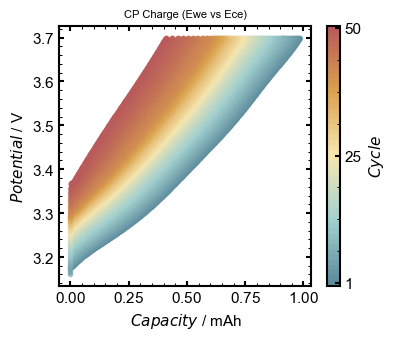

In [9]:
# Plotting of the Charging curves with the above definened function

list_of_dataframes = list_of_dataframes_CP_charge_cycling
x_values_column_name = 'Capacity (mAh)'
y_values_column_name = 'Voltage (V)'
y_ax_label = r' $ Potential $ / V  '
x_ax_label = r' $ Capacity $ / mAh '
save = 1 
name_figure = 'CP_Charge_Ewe_vs_Ece'
legend_title = 'CP Charge (Ewe vs Ece)'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title)

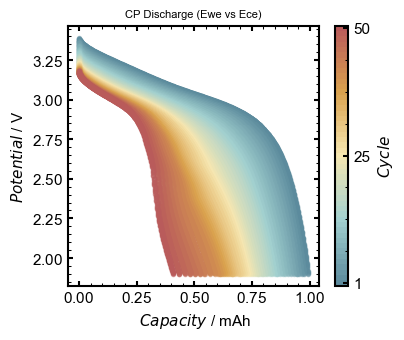

In [10]:
# Plotting of the discharging curves with the above definened function

list_of_dataframes = list_of_dataframes_CP_discharge_cycling
x_values_column_name = 'Capacity (mAh)'
y_values_column_name = 'Voltage (V)'
y_ax_label = r' $ Potential $ / V  '
x_ax_label = r' $ Capacity $ / mAh '
save = 1 
name_figure = 'CP_Discharge_Ewe_vs_Ece'
legend_title = 'CP Discharge (Ewe vs Ece)'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title)

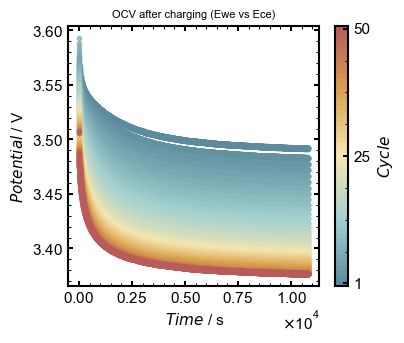

In [11]:
# Plotting of the OCV curves after charging with the above definened function

list_of_dataframes = list_of_dataframes_OCV_after_CP_step_charge_cycling
x_values_column_name = 'StepTime (seconds)'
y_values_column_name = 'Voltage (V)'
y_ax_label = r' $ Potential $ / V  '
x_ax_label = r' $ Time $ / s '
save = 1 
name_figure = 'OCV_after_charging_Ewe_vs_Ece'
legend_title = 'OCV after charging (Ewe vs Ece)'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title)

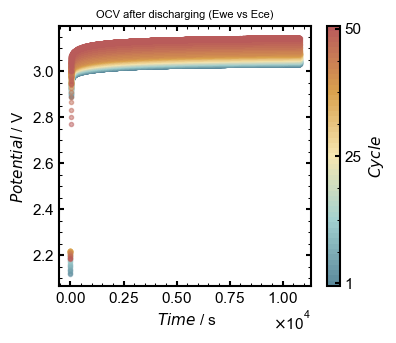

In [12]:
# Plotting of the OCV curves after discharging with the above definened function

list_of_dataframes = list_of_dataframes_OCV_after_CP_step_discharge_cycling
x_values_column_name = 'StepTime (seconds)'
y_values_column_name = 'Voltage (V)'
y_ax_label = r' $ Potential $ / V  '
x_ax_label = r' $ Time $ / s '
save = 1 
name_figure = 'OCV_after_discharging_Ewe_vs_Ece'
legend_title = 'OCV after discharging (Ewe vs Ece)'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title)